# 1. Raw data and data quality

Three smart water meters record the **cumulative volume (L)** delivered to three cafeterias of
the Víctor Levi Sasso campus (Universidad Tecnológica de Panamá): `CAF_C1`, `CAF_CENTRAL` and
`CAF_C3`. The nominal reporting interval is 15 min.

Before any consumption is computed, this notebook describes what the raw readings look like:
period covered, number of readings, real sampling interval, gaps and daily coverage.

The meter platform exports timestamps in UTC. The files in `data/` were already shifted by
−5 h to local time (Panama, UTC−5, no daylight saving time). After the shift, night-time
consumption is close to zero and the morning rise starts around 05:00, which matches the
cafeterias' operation.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

import eda_utils as u

u.set_style()
pd.set_option("display.float_format", "{:,.3f}".format)

## 1.1 Overview of the readings

In [2]:
readings = {caf: u.load_readings(caf) for caf in u.CAFETERIAS}

rows = []
for caf, r in readings.items():
    dt = u.sampling_intervals(r)
    rows.append({
        "cafeteria": caf,
        "first reading": r.index.min(),
        "last reading": r.index.max(),
        "days spanned": (r.index.max() - r.index.min()).days,
        "readings": len(r),
        "expected at 15 min": int((r.index.max() - r.index.min()) / pd.Timedelta("15min")),
        "median interval (min)": dt.median(),
        "negative steps": int((r.diff() < 0).sum()),
    })
overview = pd.DataFrame(rows).set_index("cafeteria")
overview["readings / expected (%)"] = 100 * overview["readings"] / overview["expected at 15 min"]
overview

,first reading,last reading,days spanned,readings,expected at 15 min,median interval (min),negative steps,readings / expected (%)
cafeteria,,,,,,,,
CAF_C1,2023-10-29 23:39:00,2025-06-26 09:24:00,605,4216,58119,15.000,0,7.254
CAF_CENTRAL,2023-10-29 23:55:00,2025-09-10 17:55:00,681,49024,65448,15.000,0,74.905
CAF_C3,2023-10-29 23:26:00,2025-09-10 17:56:00,681,40887,65450,15.000,0,62.471


## 1.2 Cumulative volume

The cumulative counter should only grow. Flat stretches mean no consumption (nights,
weekends, vacations); straight diagonal segments are periods without readings, where the
counter jumps from one value to the next.

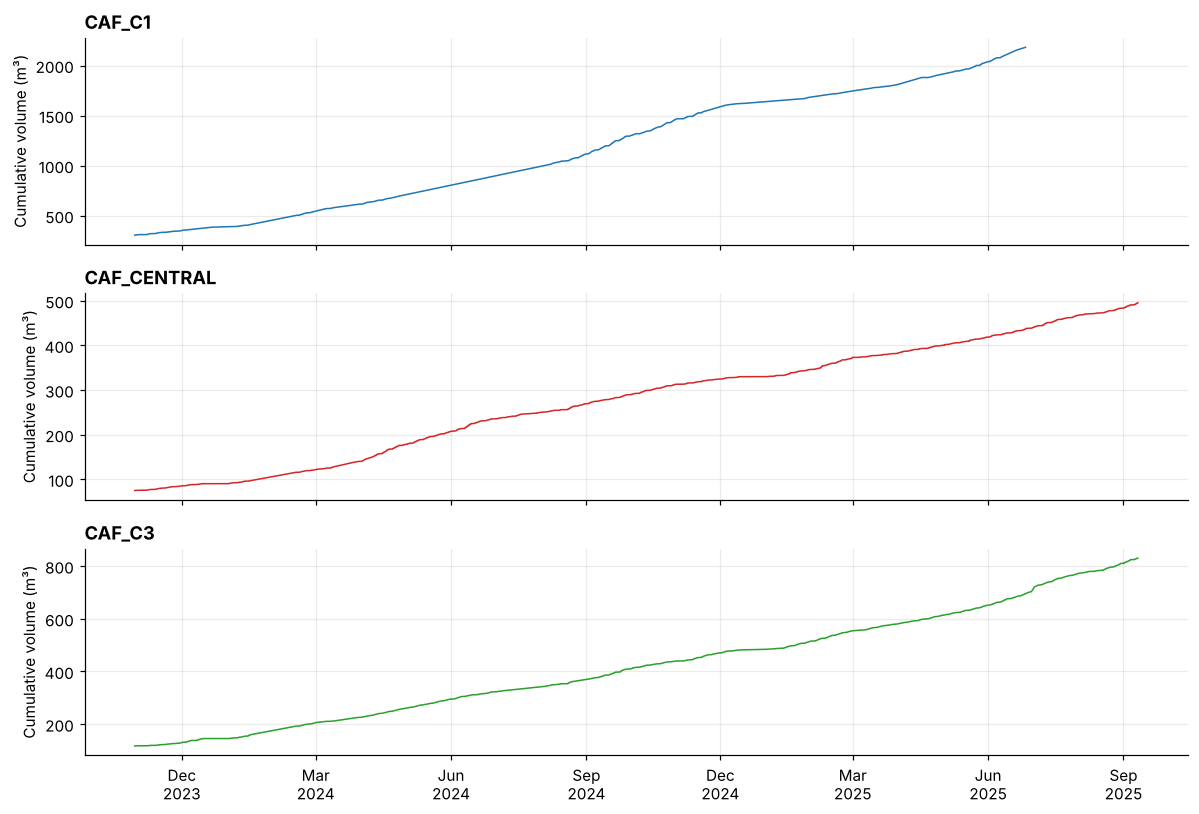

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True)
for ax, (caf, r) in zip(axes, readings.items()):
    ax.plot(r.index, r / 1000, color=u.COLORS[caf], lw=1)
    ax.set_title(caf, loc="left")
    ax.set_ylabel("Cumulative volume (m³)")
axes[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
fig.tight_layout()
u.savefig(fig, "01_cumulative_volume")

## 1.3 Real sampling interval

Share of the intervals between consecutive readings, grouped by length.

In [4]:
bins = [0, 15.5, 30.5, 60.5, 240.5, 1440.5, np.inf]
labels = ["≤15 min", "16–30 min", "31–60 min", "1–4 h", "4–24 h", ">1 day"]
intervals = pd.DataFrame({
    caf: pd.cut(u.sampling_intervals(r), bins, labels=labels).value_counts(normalize=True).sort_index() * 100
    for caf, r in readings.items()
})
intervals

,CAF_C1,CAF_CENTRAL,CAF_C3
datetime,,,
≤15 min,50.676,83.351,78.849
16–30 min,18.078,12.861,14.986
31–60 min,12.811,3.388,4.923
1–4 h,12.242,0.349,1.106
4–24 h,4.769,0.037,0.108
>1 day,1.423,0.014,0.029


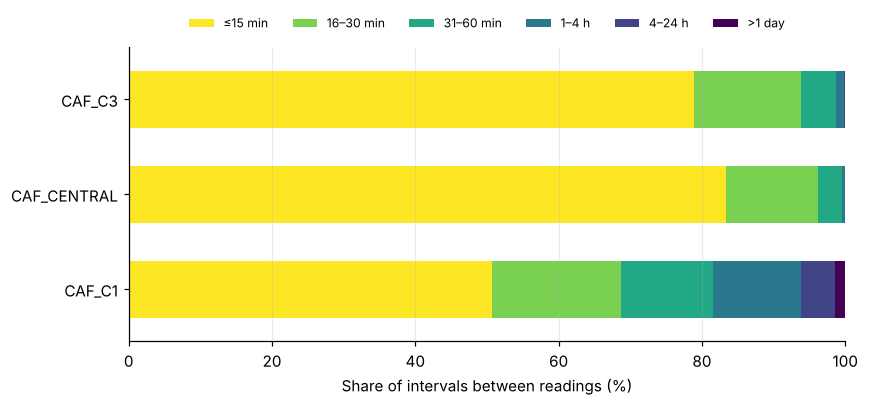

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.8))
intervals.T.plot(kind="barh", stacked=True, ax=ax, colormap="viridis_r", width=0.6)
ax.set_xlabel("Share of intervals between readings (%)")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.legend(ncol=6, bbox_to_anchor=(0.5, 1.02), loc="lower center", fontsize=8)
ax.grid(axis="y", visible=False)
fig.tight_layout()
u.savefig(fig, "01_sampling_intervals")

## 1.4 Gaps longer than one day

In [6]:
gap_rows = []
for caf, r in readings.items():
    dt = u.sampling_intervals(r)
    long = dt[dt > 1440]
    gap_rows.append({
        "cafeteria": caf,
        "gaps > 1 day": len(long),
        "days lost in those gaps": round(long.sum() / 1440, 1),
        "longest gap (days)": round(long.max() / 1440, 1) if len(long) else 0,
        "longest gap ends": long.idxmax() if len(long) else None,
    })
pd.DataFrame(gap_rows).set_index("cafeteria")

,gaps > 1 day,days lost in those gaps,longest gap (days),longest gap ends
cafeteria,,,,
CAF_C1,60,426.200,103.800,2024-08-07 17:39:00
CAF_CENTRAL,7,55.500,29.800,2024-02-15 15:40:00
CAF_C3,12,100.500,29.800,2024-02-15 14:56:00


## 1.5 Daily coverage

Daily coverage = share of the 96 nominal 15-min slots of a day that contain at least one reading.

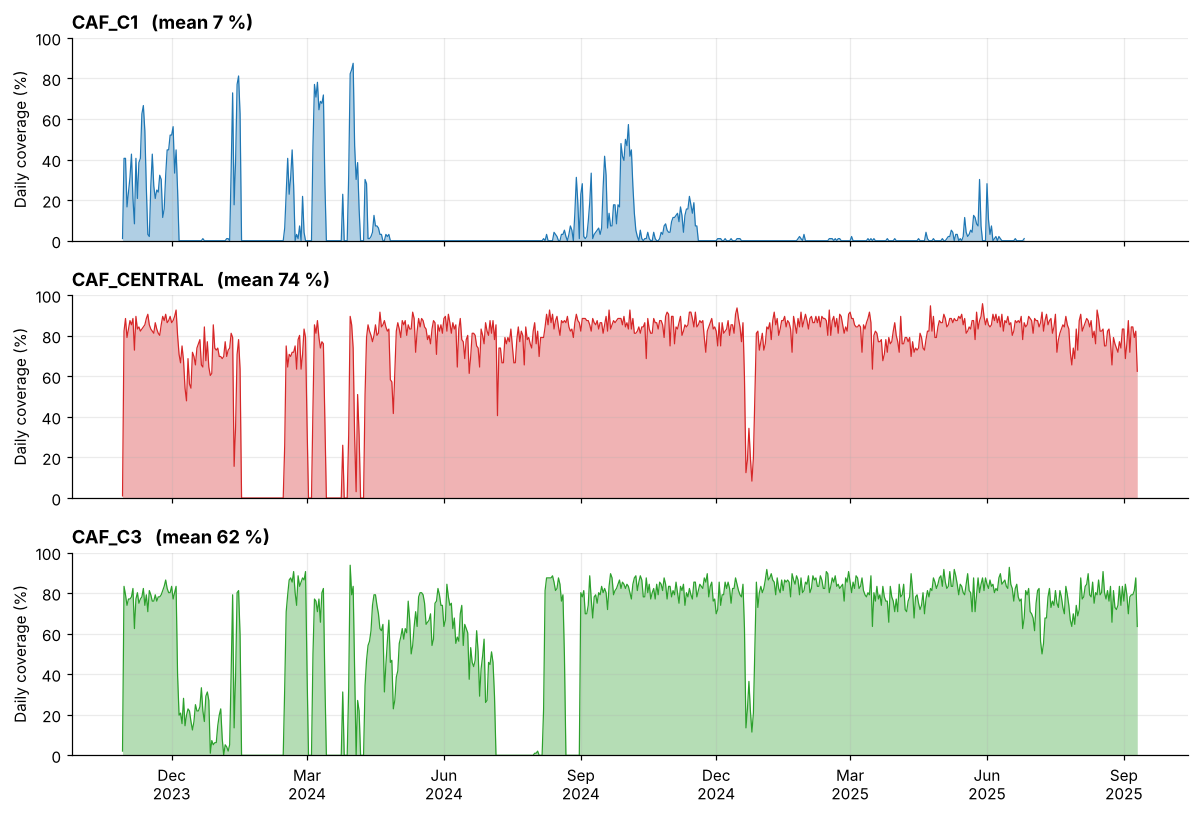

In [7]:
coverage = {}
for caf, r in readings.items():
    slots = r.resample("15min").count().gt(0)
    coverage[caf] = slots.resample("D").sum() / 96 * 100

fig, axes = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True, sharey=True)
for ax, (caf, s) in zip(axes, coverage.items()):
    ax.fill_between(s.index, 0, s.values, color=u.COLORS[caf], alpha=0.35, lw=0)
    ax.plot(s.index, s.values, color=u.COLORS[caf], lw=0.8)
    ax.set_ylim(0, 100)
    ax.set_title(f"{caf}   (mean {s.mean():.0f} %)", loc="left")
    ax.set_ylabel("Daily coverage (%)")
axes[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
fig.tight_layout()
u.savefig(fig, "01_daily_coverage")

In [8]:
pd.DataFrame({
    caf: {
        "mean daily coverage (%)": s.mean(),
        "days with ≥ 90 % coverage": int((s >= 90).sum()),
        "days with no reading": int((s == 0).sum()),
    }
    for caf, s in coverage.items()
}).T

,mean daily coverage (%),days with ≥ 90 % coverage,days with no reading
CAF_C1,7.204,0.000,365.000
CAF_CENTRAL,74.390,40.000,49.000
CAF_C3,61.949,11.000,90.000


## Observations

* `CAF_CENTRAL` and `CAF_C3` report every 15 min most of the time (83 % and 79 % of the
  intervals between readings), with a mean daily coverage of 74 % and 62 %. Both meters
  share a long outage between December 2023 and February 2024 (longest gap ≈ 30 days, ending
  15 Feb 2024); `CAF_C3` also has a long gap in June–August 2024.
* `CAF_C1` is very sparse: 4,216 readings in 605 days (7 % of the expected number), 60 gaps
  longer than one day that add up to 426 days, and a longest gap of 104 days (ending 7 Aug
  2024). Its readings stop on 26 June 2025, and no single day is complete.
* No counter ever decreased, so there are no meter resets or rollovers to correct.
* Daily coverage counts slots that contain a reading. A meter that reports every 30 min has
  50 % coverage by this measure but still allows consumption to be estimated for every 15-min
  interval (notebook 2), so the usable share of data is higher than these percentages.